# Chapter 1. Is this an ML problem at all?

*Prediction, rule or query: when a business question is a modelling problem.*

Marketing walks in with a list of questions and the word "AI" on every one of them. Some need a model; most need a query or a rule, which are cheaper, faster and easier to explain. This chapter sorts six of Kalpa's questions, all invented for teaching, with three tests you can run in your head.

By the end you can say, for any business question, whether it is a query, a rule or a prediction, and for a prediction, whether it asks "how much" (regression) or "will they" (classification).

**Search terms:** when to use machine learning, ML problem framing, rules versus machine learning, regression versus classification.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

## Six questions from Kalpa, invented for teaching

**Predict before you run.** How many of the six need a trained model? (a) all six (b) four (c) two (d) none

In [2]:
# Six of Kalpa's questions (invented), with the three facts that decide each one.
qs = pd.DataFrame([
    ("How many members bought in September?",                         True,  False, False),
    ("Which members will buy again in the next 90 days?",              False, False, True),
    ("Remind every member whose cart was abandoned yesterday",         False, True,  False),
    ("What was the average basket in Pune last quarter?",              True,  False, False),
    ("How much will each member spend next quarter?",                  False, False, True),
    ("Hold any order above Rs 50,000 from a member who joined this week", False, True, False),
], columns=["question", "answer_already_in_data", "condition_known", "target_later_and_decision_moves"])
print(qs.to_string(index=False))

                                                         question  answer_already_in_data  condition_known  target_later_and_decision_moves
                            How many members bought in September?                    True            False                            False
                Which members will buy again in the next 90 days?                   False            False                             True
           Remind every member whose cart was abandoned yesterday                   False             True                            False
                What was the average basket in Pune last quarter?                    True            False                            False
                    How much will each member spend next quarter?                   False            False                             True
Hold any order above Rs 50,000 from a member who joined this week                   False             True                            False


## The three tests, in order

1. **Is the answer already sitting in the data?** Then it is a **query**: count, sum or average what happened.
2. **Can someone write the decision down as a condition?** Then it is a **rule**: an if-then that needs no learning.
3. **Otherwise, are all three present:** an input known now, a target known only later, and a decision that changes with the score? Then it is a **prediction**, and a model earns its place.

In [3]:
# Run the three tests in order, then split predictions into "how much" and "will they".
def kind(row):
    if row.answer_already_in_data:
        return "query"
    if row.condition_known:
        return "rule"
    if row.target_later_and_decision_moves:
        return "prediction"
    return "not yet framed"

qs["kind"] = qs.apply(kind, axis=1)
qs["family"] = np.where(qs["kind"] != "prediction", "",
                        np.where(qs["question"].str.startswith("How much"), "regression: how much", "classification: will they"))
print(qs[["question", "kind", "family"]].to_string(index=False))
check("two queries, two rules, two predictions", qs["kind"].value_counts().to_dict() == {"query": 2, "rule": 2, "prediction": 2})
check("every question got a kind", (qs["kind"] != "not yet framed").all())

                                                         question       kind                    family
                            How many members bought in September?      query                          
                Which members will buy again in the next 90 days? prediction classification: will they
           Remind every member whose cart was abandoned yesterday       rule                          
                What was the average basket in Pune last quarter?      query                          
                    How much will each member spend next quarter? prediction      regression: how much
Hold any order above Rs 50,000 from a member who joined this week       rule                          
PASS  two queries, two rules, two predictions
PASS  every question got a kind


**What happened.** The answer is (c): only two of the six need a model. The 90-day repeat question is classification (will they), and next-quarter spend is regression (how much). The two counts are queries, and the reminder and the order hold are rules.

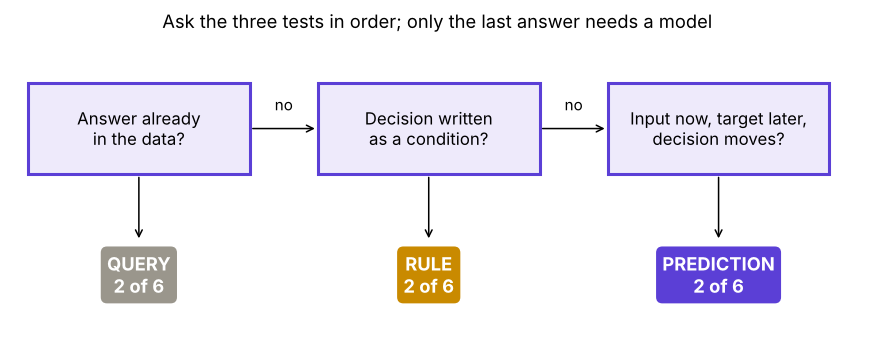

In [4]:
# Draw the sorting as a picture: three tests, three answers.
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.axis("off")
boxes = [(0.02, "Answer already\nin the data?"), (0.36, "Decision written\nas a condition?"), (0.70, "Input now, target later,\ndecision moves?")]
for x, t in boxes:
    ax.add_patch(plt.Rectangle((x, 0.55), 0.26, 0.3, fc="#EEEAFB", ec="#5B3FD6", lw=2))
    ax.text(x + 0.13, 0.70, t, ha="center", va="center", fontsize=11)
for x, t, c in [(0.02, "QUERY\n2 of 6", "#9A968C"), (0.36, "RULE\n2 of 6", "#C98A00"), (0.70, "PREDICTION\n2 of 6", "#5B3FD6")]:
    ax.text(x + 0.13, 0.22, t, ha="center", va="center", fontsize=12, color="white", fontweight="bold",
            bbox=dict(boxstyle="round", fc=c, ec=c))
    ax.annotate("", xy=(x + 0.13, 0.33), xytext=(x + 0.13, 0.55), arrowprops=dict(arrowstyle="->"))
for x in (0.28, 0.62):
    ax.annotate("", xy=(x + 0.08, 0.70), xytext=(x, 0.70), arrowprops=dict(arrowstyle="->"))
    ax.text(x + 0.04, 0.76, "no", ha="center", fontsize=10)
ax.set_title("Ask the three tests in order; only the last answer needs a model", fontsize=12)
plt.show()

## When does a rule stop being enough?

Google's Rules of Machine Learning open with "Don't be afraid to launch a product without machine learning" and estimate that a heuristic gets you about half of the gain a model would (developers.google.com/machine-learning/guides/rules-of-ml, verified 28 October 2026). A rule stays the right answer until the business can name what it leaves on the table: members the rule nudges who were going to buy anyway, or members it misses who would have bought with a nudge.

**The flip.** "Use a rule" holds while the rule's misses are cheap. Once a missed repeat buyer costs Rs 1,200 of margin against a Rs 40 nudge (the row's invented numbers), a score that ranks members starts paying for itself, and the question becomes a prediction.

**Uber, for the interview.** Uber's DeepETA post (uber.com/blog/deepeta-how-uber-predicts-arrival-times, verified 28 October 2026) frames arrival time this way: the routing engine already gives an estimate, a rule built from the map, and the model predicts only the residual, how wrong the routing engine will be. The rule stays; the model corrects it.

## What did this chapter establish?

| Question | Answer |
|---|---|
| What makes a question a query? | the answer already sits in the data |
| What makes it a rule? | someone can write the decision as a condition |
| What makes it a prediction? | input known now, target known later, a decision that moves with the score |
| Regression or classification? | "how much" is regression; "will they" is classification |

**Interview line:** "A business question is a modelling problem when the input is known at decision time, the target is known later, and the decision changes with the prediction; if the answer is already in the data it is a query, and if I can write the decision down it is a rule."